# 07 Results, step 1: a strong baseline - how good can an AKI model get on this data?

**Step 1 of the project: build a strong baseline.** The locked model is accurate and calibrated, and with
creatinine-defined AKI and this training set it is close to its ceiling: a GRU sequence model, other feature
statistics and fewer inputs give no meaningful gain. Notebook 08 moves this baseline to another record system (Step 2)
and repairs its alerts with local data (Step 3).

It only reads committed aggregate tables and figures (no MIMIC access needed). Numbers are explained in
`docs/FINAL-ANALYSES.md`, Part 1.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "pipeline" else Path.cwd()
R = ROOT / "artifacts" / "reports"
FIG = R / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

def show(name, width=820):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

## System overview and cohort

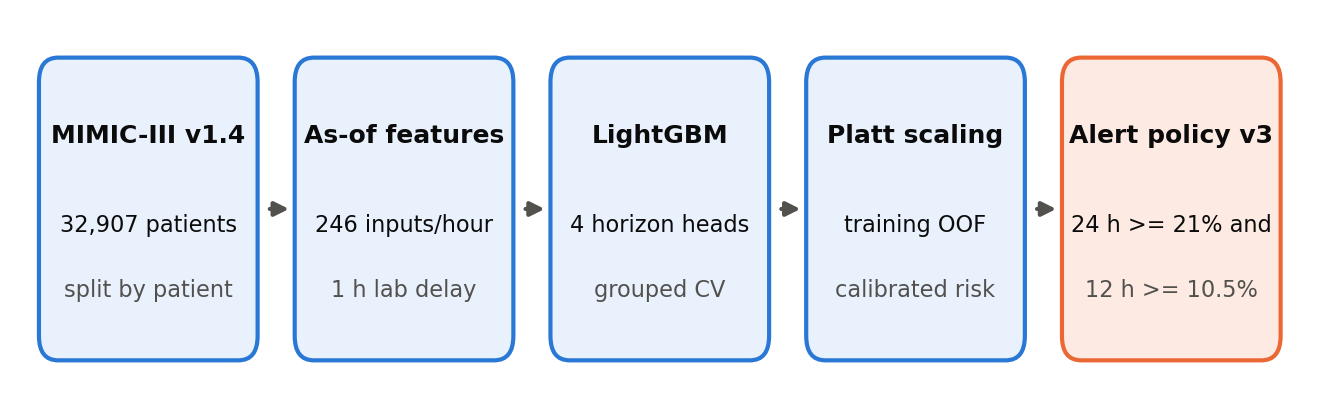

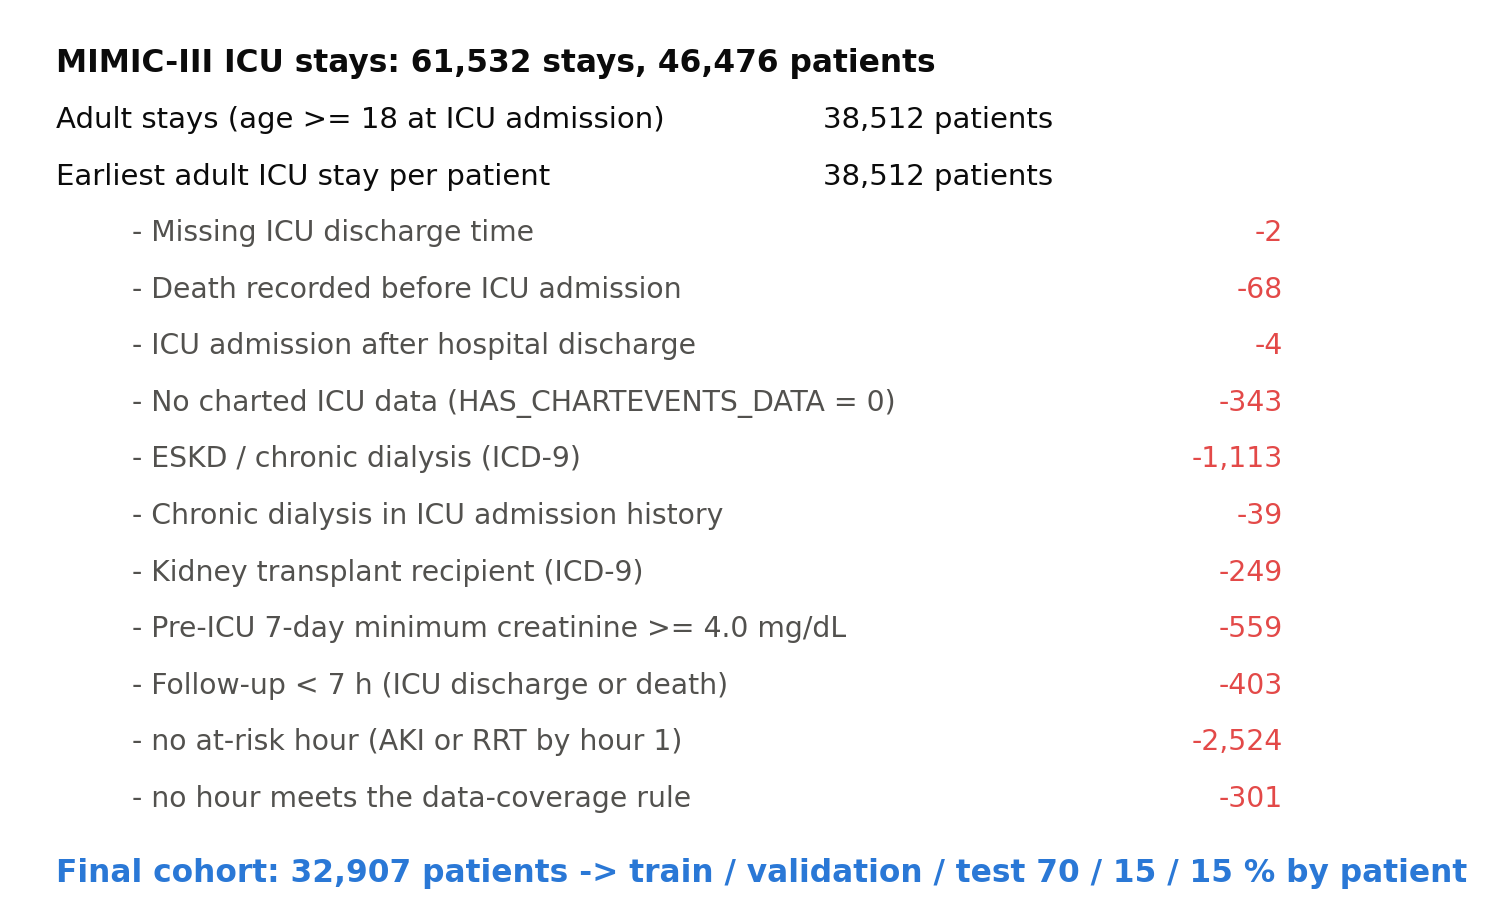

split,train,validation,test,all
patients,22998,4950,4959,32907
age_years_median_iqr,65.4 [52.1-77.8],65.4 [52.4-77.7],65.8 [52.0-78.5],65.4 [52.1-77.9]
male_pct,56.6,57.4,55.7,56.6
emergency_admission_pct,80.6,80.3,81.1,80.6
icu_los_hours_median_iqr,49.5 [28.6-95.4],49.3 [28.4-95.2],50.8 [28.7-98.7],49.7 [28.6-95.9]
icu_death_pct,6.9,6.6,6.4,6.8
carevue_pct,57.2,57.2,57.2,57.2
metavision_pct,42.7,42.6,42.6,42.7
creatinine_aki_pct,22.9,23.1,23.3,23.0
aki_stage1_pct,16.5,16.9,16.9,16.6


In [2]:
show("fig_pipeline")
show("fig_cohort_flow", 640)
pd.read_csv(R / "eda_v1" / "table1_by_split.csv").set_index("split").T

## 1.1 What the data look like (training split)
AKI is early (median onset 31 h), creatinine rises before onset, and measurement intensity itself carries signal.

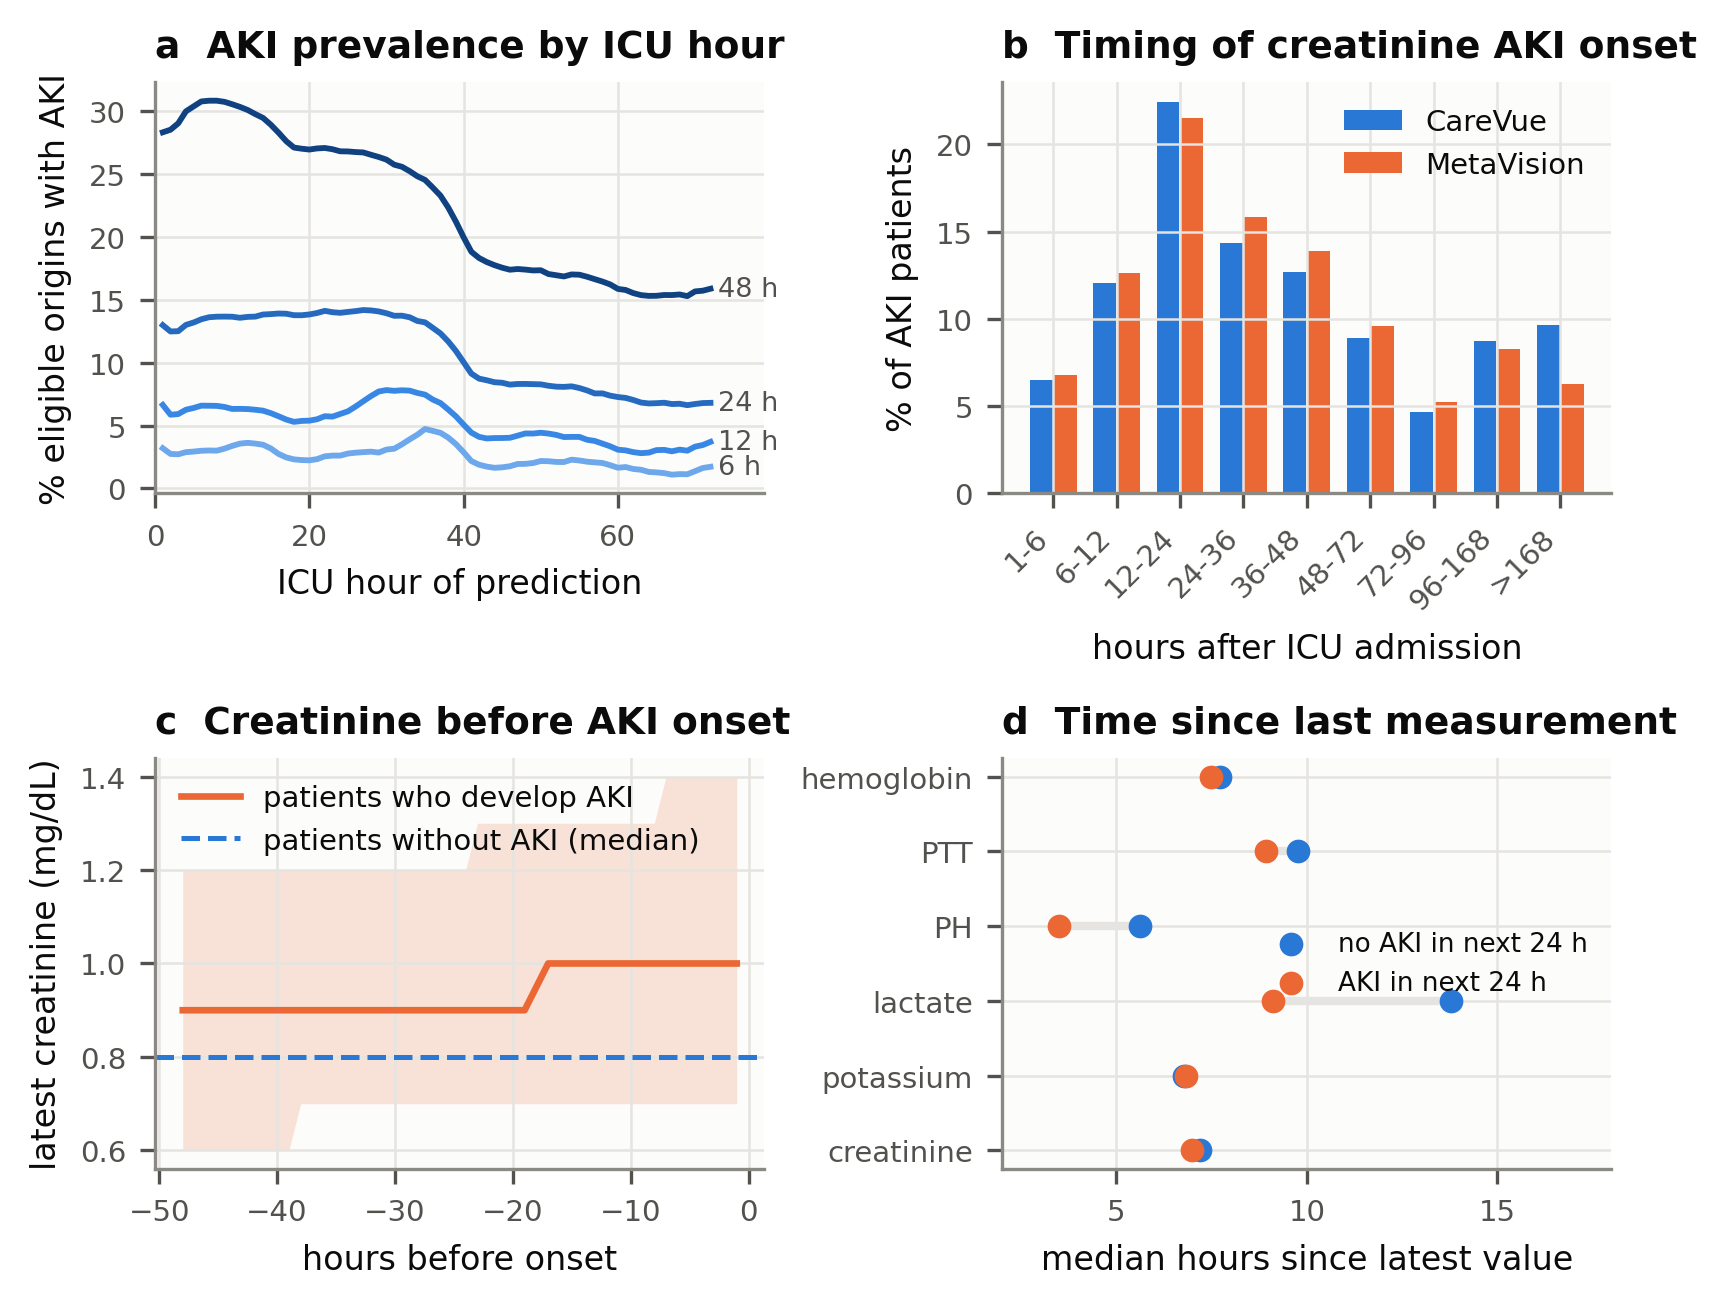

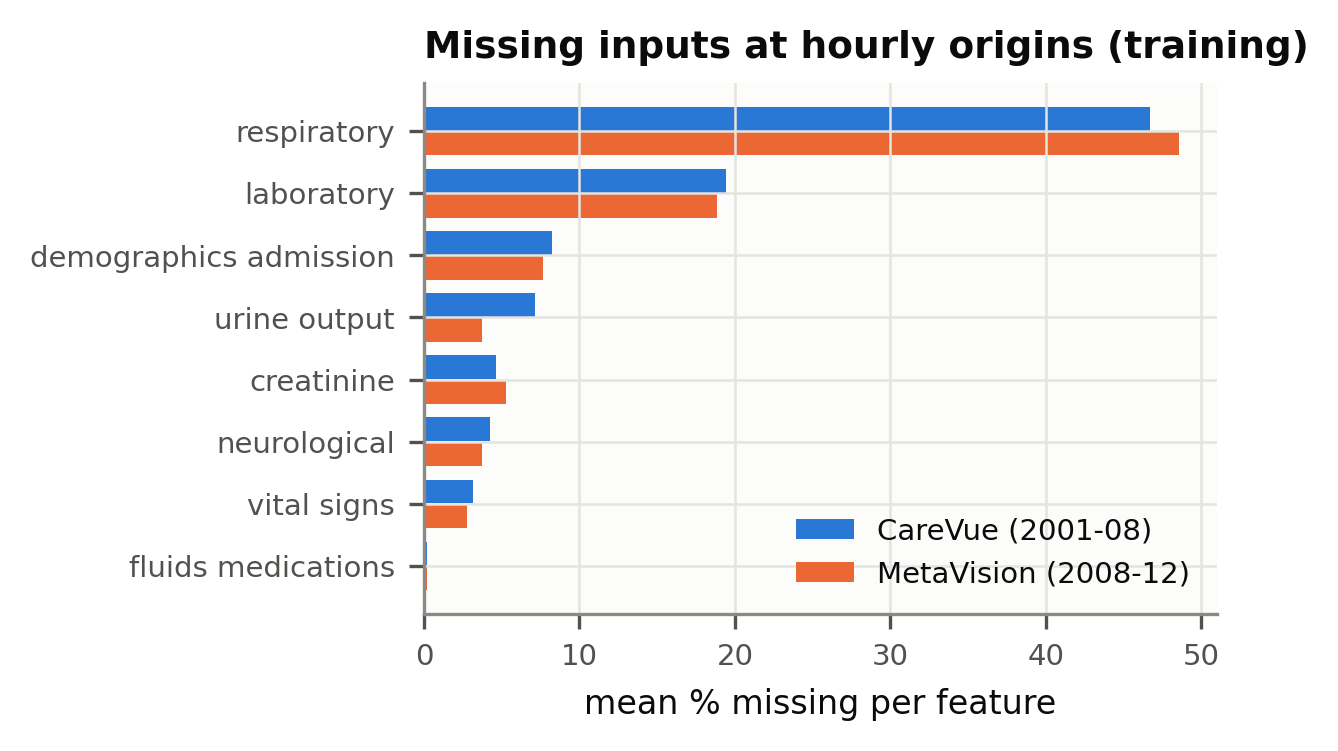

In [3]:
show("fig_eda")
show("fig_missingness", 560)

## 1.2 Discrimination, calibration and baselines (test split)
The locked LightGBM beats every baseline; its probabilities are calibrated (observed / expected 0.98).

horizon_h,6,12,24,48
label,,,,
LightGBM no_dc (stored features),0.866,0.841,0.817,0.792
LightGBM no_dc (locked system),0.866,0.841,0.817,0.792
LightGBM full,0.864,0.839,0.814,0.793
XGBoost full,0.863,0.839,0.814,0.792
Random forest full,0.843,0.820,0.794,0.778
Logistic regression full,0.819,0.805,0.788,0.774
Creatinine-only logistic regression,0.718,0.714,0.703,0.684
Creatinine rise from 48 h minimum (score),0.636,0.633,0.618,0.581


,model,auroc,auroc_ci_low,auroc_ci_high,auroc_minus_primary,delta_ci_low,delta_ci_high
16,primary,0.817,0.803,0.831,NaN,NaN,NaN
17,lightgbm__no_dc,0.817,0.803,0.831,6.196e-05,-1.776e-05,1.534e-04
18,lightgbm__full,0.814,0.799,0.829,-2.968e-03,-5.740e-03,7.737e-05
19,xgboost__full,0.814,0.800,0.829,-3.322e-03,-6.744e-03,4.881e-04
20,rf__full,0.794,0.779,0.809,-2.304e-02,-2.885e-02,-1.740e-02
21,lr__full,0.788,0.771,0.804,-2.927e-02,-3.870e-02,-2.053e-02
22,creatinine_lr,0.703,0.684,0.721,-1.144e-01,-1.284e-01,-9.903e-02
23,creatinine_rise,0.618,0.603,0.634,-1.991e-01,-2.155e-01,-1.793e-01


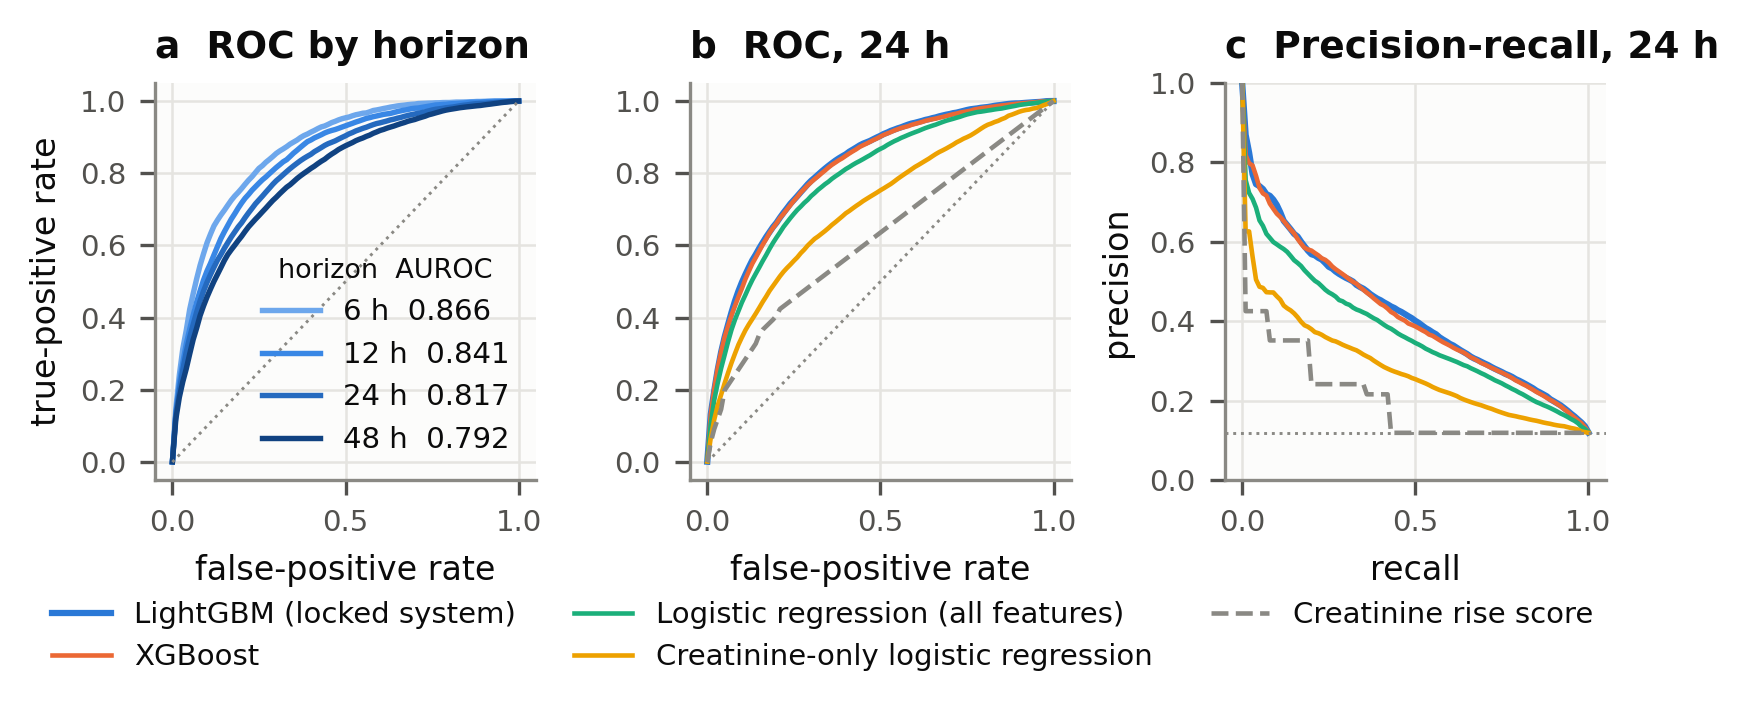

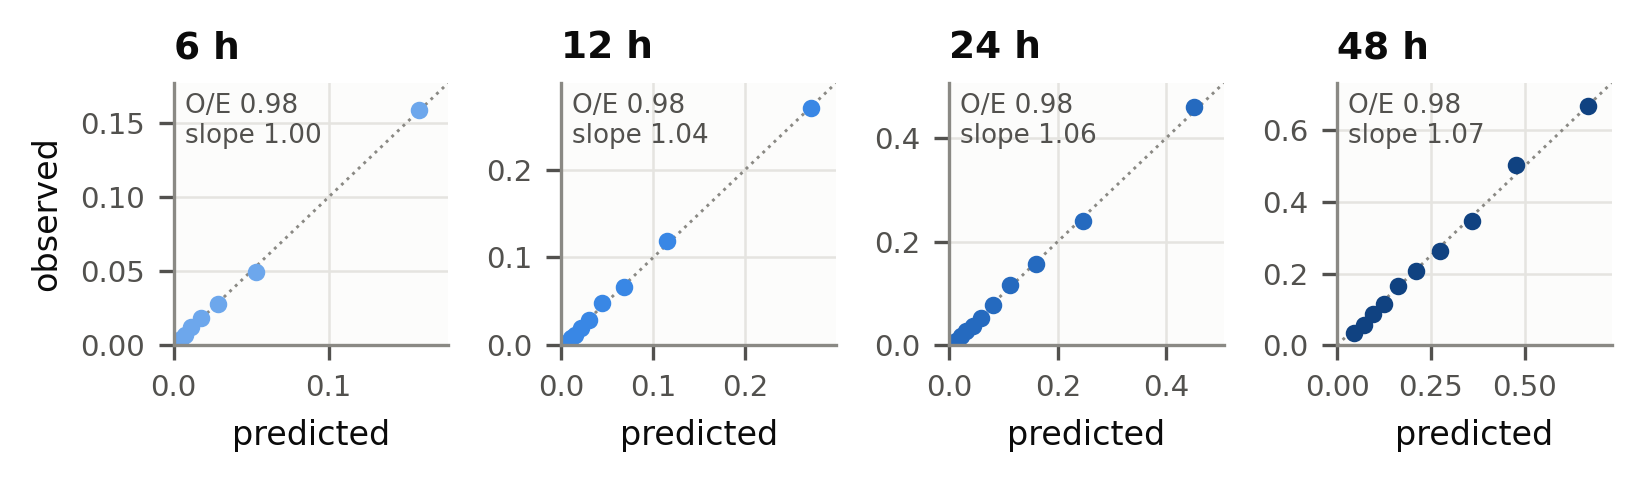

In [4]:
b = pd.read_csv(R / "final_analyses_v1" / "baseline_metrics.csv")
display(b.pivot(index="label", columns="horizon_h", values="auroc").sort_values(24, ascending=False))
d = pd.read_csv(R / "final_analyses_v1" / "baseline_auroc_differences.csv")
display(d[d["horizon_h"] == 24][["model", "auroc", "auroc_ci_low", "auroc_ci_high", "auroc_minus_primary", "delta_ci_low", "delta_ci_high"]])
show("fig_roc_pr")
show("fig_calibration")

## 1.3 Is there headroom? GRU sequence model (validation only; decision: stop)
A GRU alone is 0.009 AUROC worse; an ensemble gains only +0.008, below the prespecified bar.

In [5]:
m = pd.read_csv(R / "sequence_model_v1" / "validation_metrics.csv")
display(m.pivot(index="model", columns="horizon_h", values="auroc"))
display(pd.read_csv(R / "sequence_model_v1" / "validation_auroc_differences.csv"))

horizon_h,6,12,24,48
model,,,,
ensemble,0.873,0.848,0.817,0.790
gru,0.855,0.830,0.800,0.773
gru_seed1,0.847,0.821,0.792,0.766
gru_seed2,0.849,0.824,0.794,0.769
gru_seed3,0.844,0.820,0.790,0.765
lightgbm_locked,0.865,0.839,0.809,0.782


,horizon_h,comparison,auroc_difference,ci_low,ci_high
0,6,gru_minus_lightgbm,-0.010,-0.017,-0.001
1,6,ensemble_minus_lightgbm,0.008,0.005,0.012
2,12,gru_minus_lightgbm,-0.009,-0.017,-0.001
3,12,ensemble_minus_lightgbm,0.008,0.005,0.012
4,24,gru_minus_lightgbm,-0.009,-0.019,0.002
5,24,ensemble_minus_lightgbm,0.008,0.004,0.013
6,48,gru_minus_lightgbm,-0.009,-0.019,0.002
7,48,ensemble_minus_lightgbm,0.008,0.003,0.013


## 1.4 Which inputs does the model need? Feature ablation (validation only)
The top 100 of 246 inputs lose 0.003 AUROC at 6-24 h and 0.005 at 48 h; with fewer inputs the loss grows quickly. The signal is spread over many inputs: creatinine is the most important group, but without it the model still reaches AUROC 0.780 at 24 h, against 0.70 for a creatinine-only model.

,horizon_h,6,12,24,48
variant,n_inputs,,,,
drop_creatinine,233,-0.033,-0.034,-0.029,-0.017
drop_demographics_admission,230,-0.001,-0.002,-0.002,-0.002
drop_fluids_medications_interventions,228,-0.007,-0.005,-0.005,-0.002
drop_laboratory_other,145,-0.011,-0.010,-0.008,-0.010
drop_neurological_respiratory,238,-0.004,-0.001,-0.006,-0.004
drop_urine_output,238,-0.008,-0.006,-0.003,-0.004
drop_vital_signs,165,-0.008,-0.007,-0.009,-0.007
top_10,10,-0.091,-0.066,-0.049,-0.055
top_100,100,-0.003,-0.003,-0.003,-0.005


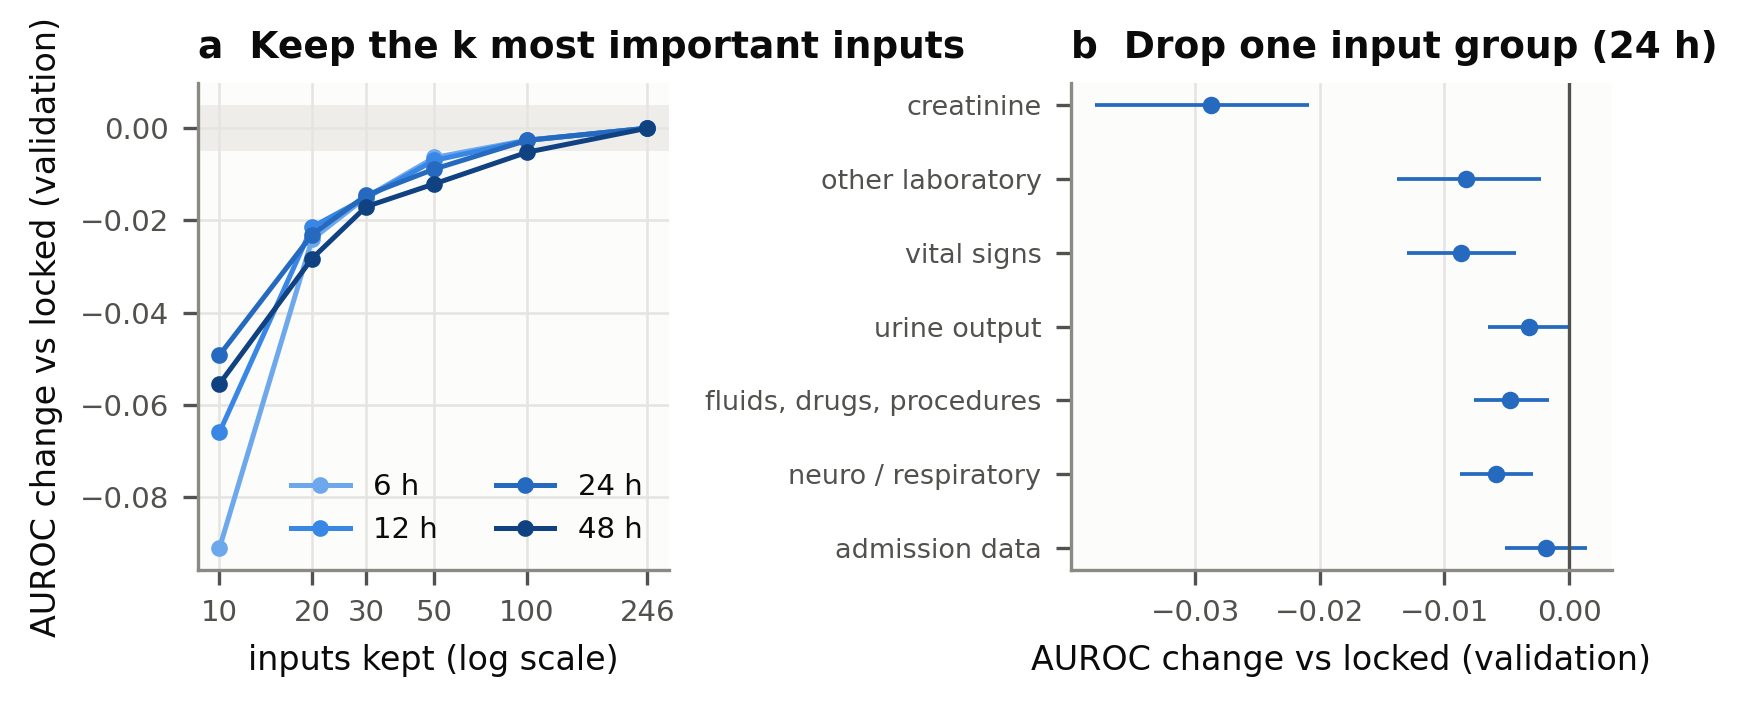

In [6]:
a = pd.read_csv(R / "feature_ablation_v1" / "validation_differences.csv")
display(a.pivot(index=["variant", "n_inputs"], columns="horizon_h", values="auroc_difference").round(3))
show("fig_feature_ablation")

## What drives the predictions, and how robust they are (from the locked test evaluation, notebook 06)

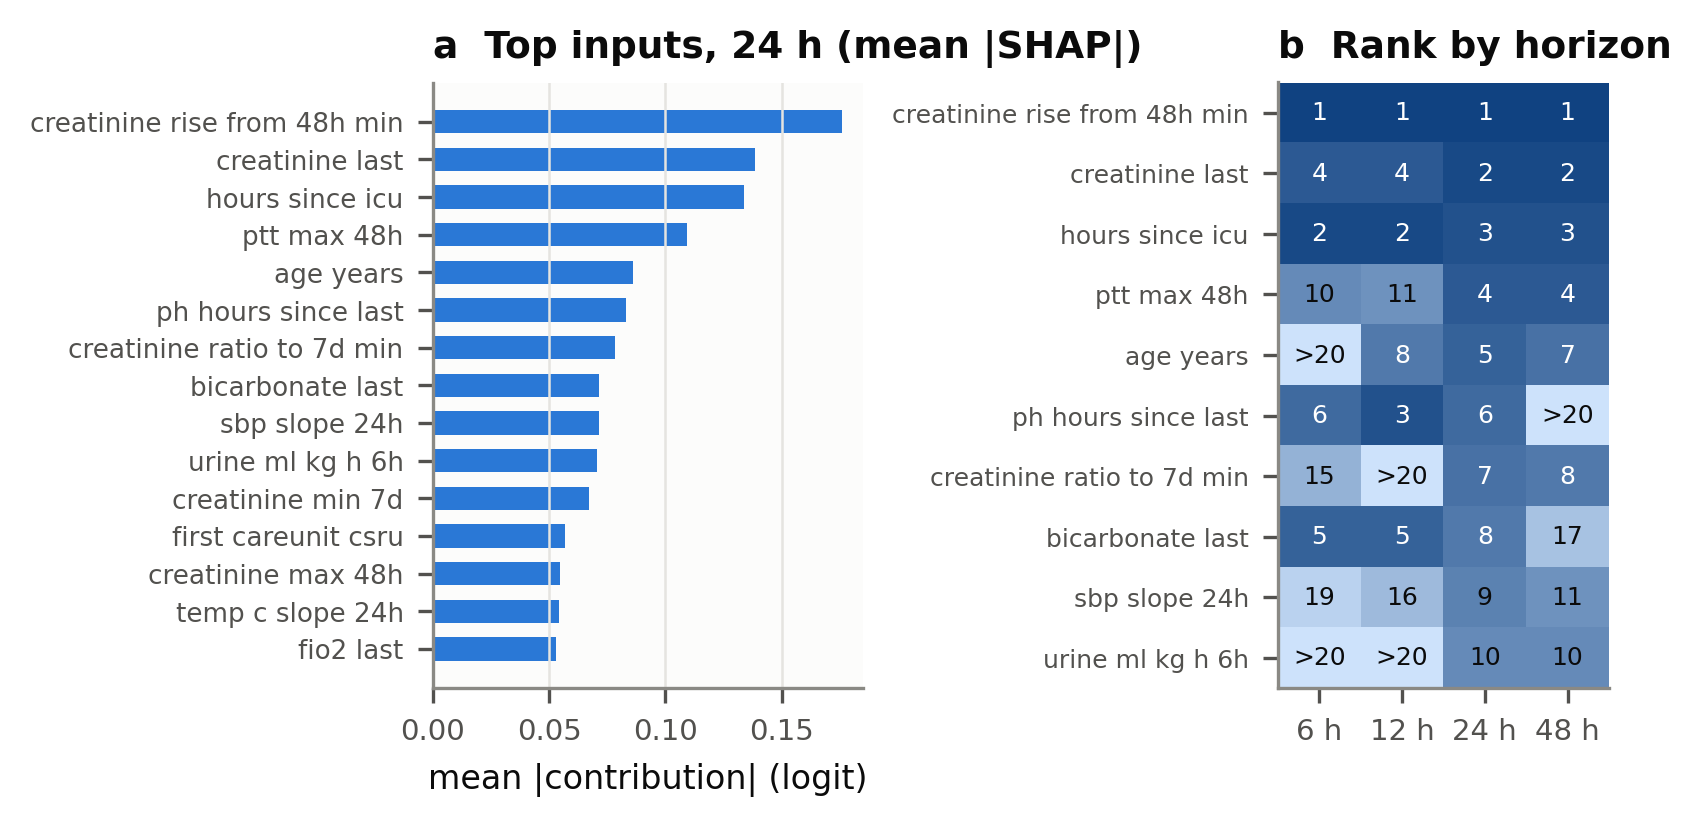

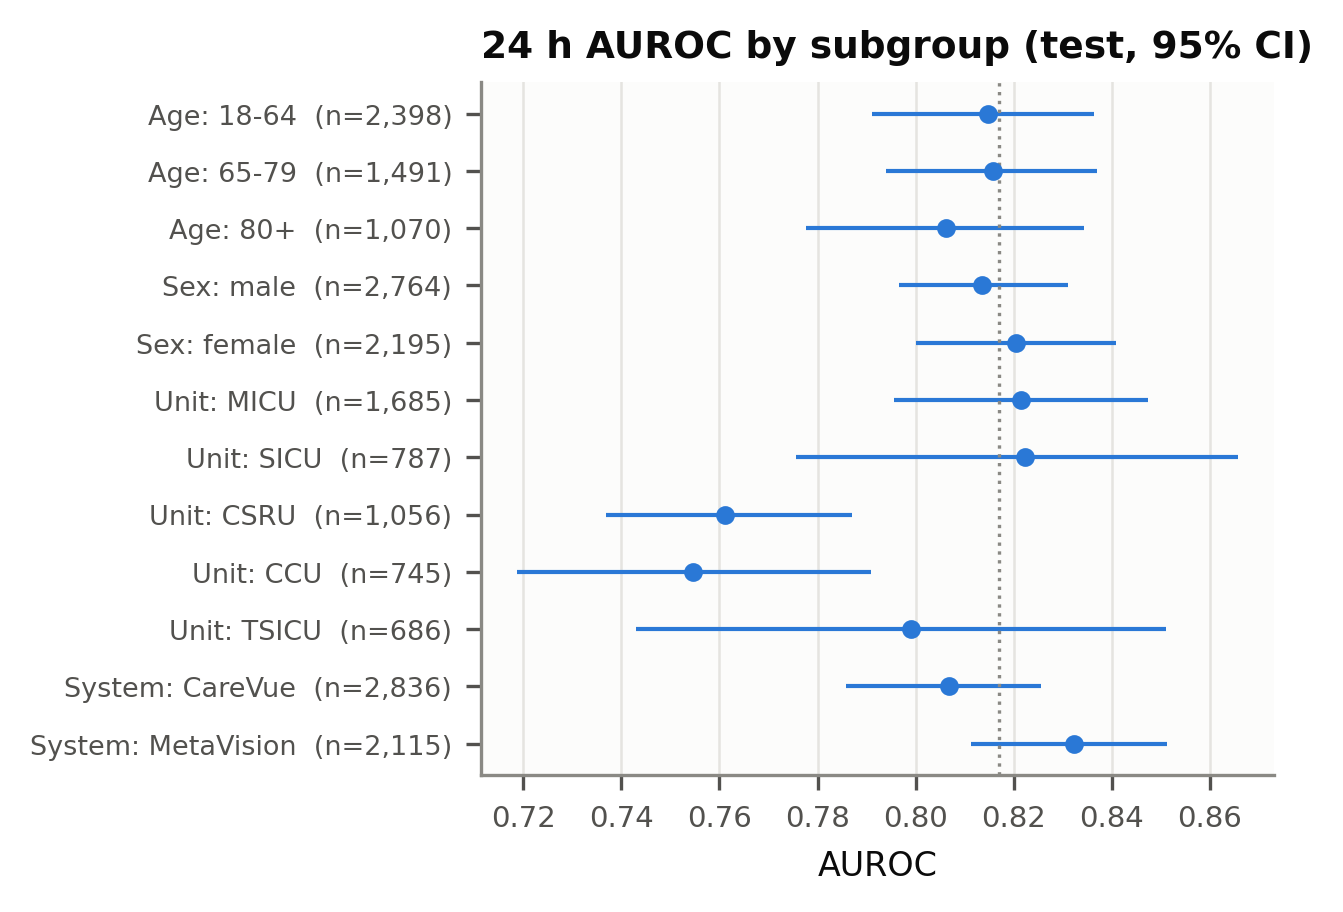

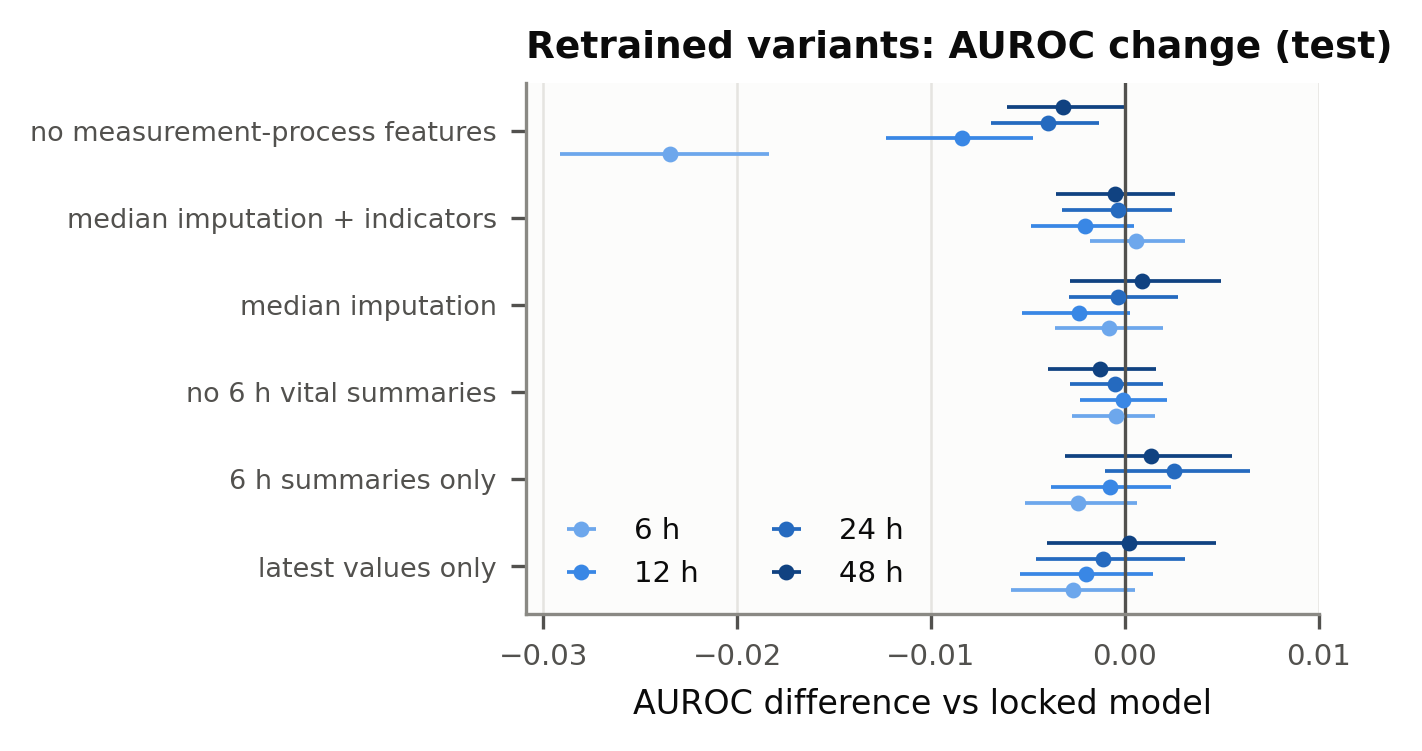

In [7]:
show("fig_shap")
show("fig_subgroups", 560)
show("fig_retrain_sensitivity", 560)